# Código original

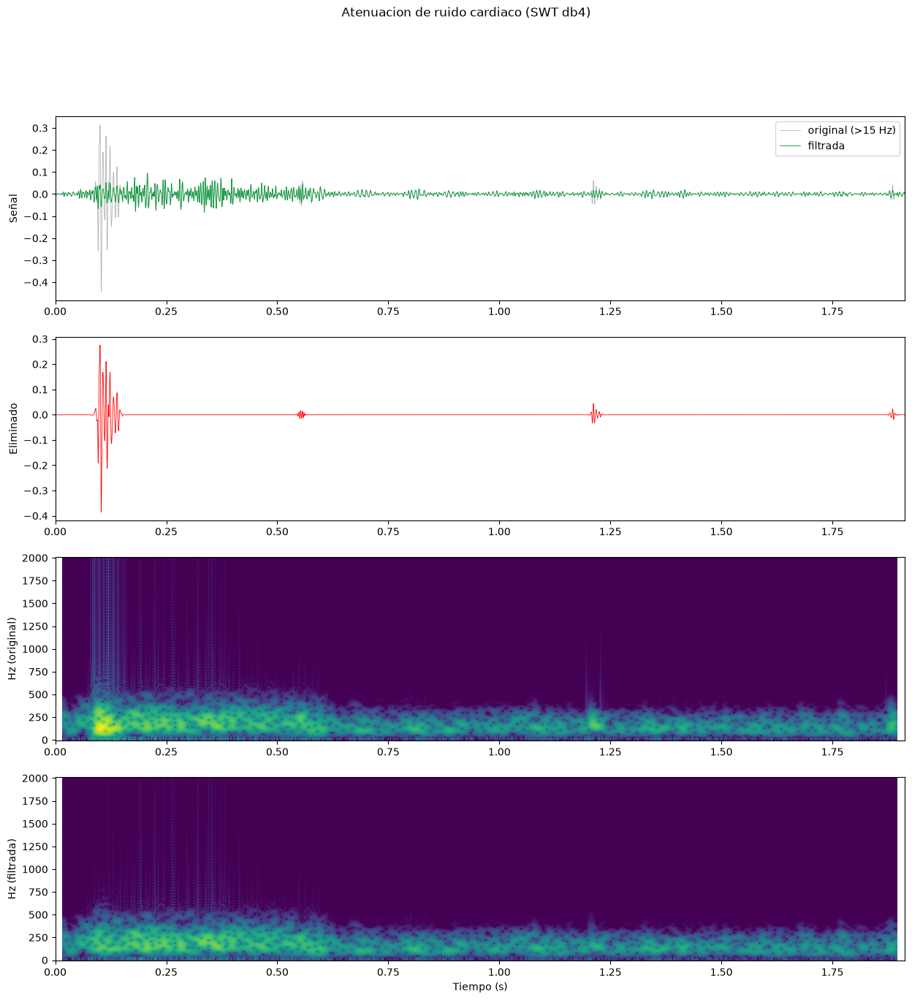

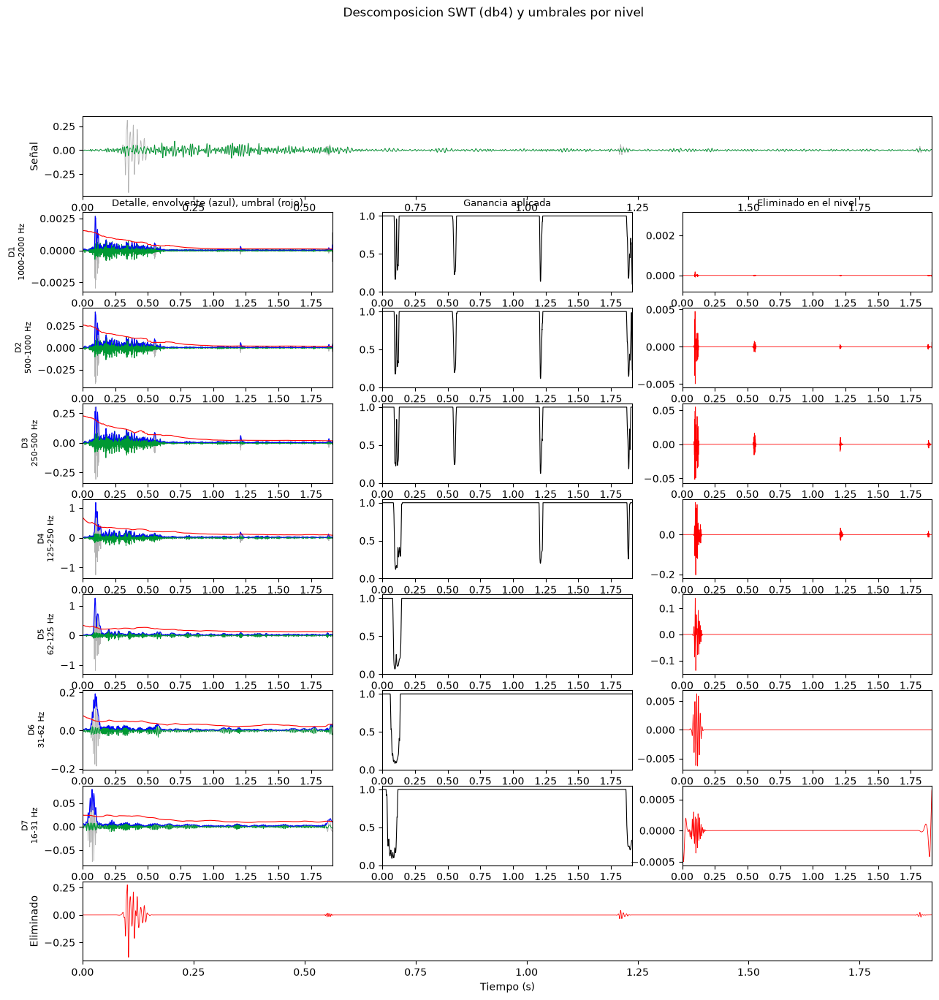

In [1]:
"""
soundwaveletSWT  Atenua los ruidos cardiacos en el sonido respiratorio

    y = soundwaveletSWT(x, fs)
    y, mascara = soundwaveletSWT(x, fs, dibujar)

    Version en Python de soundwaveletSWT.m. Se han mantenido los mismos
    nombres de variables para poder comparar linea a linea con MATLAB.

    Descompone la señal con la SWT (db4) hasta que la aproximacion queda por
    debajo de unos 15 Hz. En cada nivel se calcula la envolvente del detalle y
    se compara con un nivel de referencia, que es la mediana de la envolvente
    entre 0.1 y 0.4 s a cada lado de la muestra. La zona central se deja fuera
    para que el propio ruido cardiaco no entre en la referencia. Donde la
    envolvente pasa de K veces la referencia, se baja la amplitud del detalle
    hasta el nivel de fondo.

    Entradas
      x        señal de sonido (vector, o matriz muestras x canales)
      fs       frecuencia de muestreo en Hz
      dibujar  0  no dibuja
               1  señal original y filtrada, lo eliminado y los
                  espectrogramas antes y despues (por defecto)
               2  ademas la descomposicion nivel a nivel: detalle con su
                  envolvente y umbral, ganancia aplicada y lo que se quita
                  en cada nivel

    Salidas
      y        señal filtrada, misma longitud que x. Sin la componente por
               debajo de 15 Hz
      mascara  matriz logica niveles x muestras con las zonas tocadas
               (fila 0 = nivel 1)

    Ejemplo
      from scipy.io import wavfile
      import matplotlib.pyplot as plt
      fs, x = wavfile.read('11782.wav')
      x = x/32768          # wavfile da enteros, audioread de MATLAB normaliza
      y, mascara = soundwaveletSWT(x, fs, 2)
      plt.show()

    Los parametros (K, ventana, niveles...) estan al principio del codigo.

    Necesita numpy, scipy, matplotlib y PyWavelets (pip install PyWavelets)

    Los niveles se numeran 1..n como en MATLAB (niveles=range(3,7) es el
    3:6 de MATLAB), pero las filas de las matrices empiezan en 0.
"""

import numpy as np
import pywt
from scipy.signal import hilbert, spectrogram
from scipy.ndimage import uniform_filter1d
import matplotlib.pyplot as plt


def referencia(env, Lb, Ub):
    # Mediana de env en [j-Ub, j-Lb] y [j+Lb, j+Ub] para cada muestra j.
    # Es el bucle de MATLAB pero por bloques, que en Python el bucle
    # muestra a muestra es muy lento. Fuera de la señal se rellena con
    # NaN y nanmedian no los cuenta, igual que el indices>0 & indices<=Ntot
    Ntot = len(env)
    Lw = Ub - Lb + 1
    pad = np.concatenate((np.full(Ub, np.nan), env, np.full(Ub, np.nan)))
    ventanas = np.lib.stride_tricks.sliding_window_view(pad, Lw)
    R = np.empty(Ntot)
    bloque = 2000
    for a in range(0, Ntot, bloque):
        j = np.arange(a, min(a + bloque, Ntot))
        izq = ventanas[j]               # empieza en j-Ub
        der = ventanas[j + Ub + Lb]     # empieza en j+Lb
        R[j] = np.nanmedian(np.hstack((izq, der)), axis=1)
    return R


def soundwaveletSWT(x, fs, dibujar=1):

    x = np.asarray(x, dtype=float)
    if x.ndim > 1 and min(x.shape) > 1:
        x = x[:, 0]                     # si es estereo, primer canal
    x = x.ravel()
    x = x - np.mean(x)
    N = len(x)

    # parametros
    n = round(np.log(fs/15)/np.log(2)) - 1   # como en emgwavelet
    niveles = range(1, n + 1)   # niveles que se tocan. Con range(3,7) a 4 kHz solo 31-500 Hz
    K = 5                       # umbral = K * referencia
    Lb = round(0.1*fs)
    Ub = round(0.4*fs)
    Gfac = 1.5
    # Gfac es el nivel al que se recorta el evento, en veces la referencia R.
    # Dentro de la mascara la envolvente se deja en min(env,Gfac*R):
    # K decide donde se actua, Gfac cuanto se baja.
    # Gfac=0 pone los coeficientes a cero y deja hueco
    # Gfac=1 deja el evento en la mediana del fondo, suena algo hundido
    # Gfac=1.5 lo deja mas o menos al nivel del sonido respiratorio
    # Gfac=K solo recorta hasta el umbral, casi no atenua
    # Si en "Eliminado en el nivel" queda ruido cardiaco, bajarlo.
    # Si la señal filtrada tiene huecos donde estaba el S1/S2, subirlo.
    Lenv = round(0.004*fs)   # suavizado de la envolvente
    Ldil = round(0.02*fs)    # se ensancha la mascara 10 ms a cada lado
    Lg = round(0.005*fs)     # suavizado de la ganancia

    # la SWT necesita longitud multiplo de 2^n, relleno por simetria
    Ntot = int(np.ceil(N/2**n))*2**n
    npad = Ntot - N
    xp = np.concatenate((x, x[N - npad:][::-1]))

    # pywt devuelve [(cAn,cDn),...,(cA1,cD1)], se le da la vuelta para que
    # la fila 0 sea el nivel 1 como en MATLAB
    coef = pywt.swt(xp, 'db4', level=n)
    cA = np.array([c[0] for c in coef[::-1]])
    cD = np.array([c[1] for c in coef[::-1]])

    Dm = cD.copy()
    env = np.zeros((n, Ntot))
    R = np.full((n, Ntot), np.nan)
    g = np.ones((n, Ntot))
    mascara = np.zeros((n, Ntot), dtype=bool)

    for i in range(n):
        env[i] = uniform_filter1d(np.abs(hilbert(cD[i])), Lenv)

    for nivel in niveles:
        i = nivel - 1
        R[i] = referencia(env[i], Lb, Ub)
        m = env[i] > K*R[i]
        m = np.convolve(m.astype(float), np.ones(Ldil), 'same') > 0.5
        mascara[i] = m
        gi = np.ones(Ntot)
        gi[m] = np.minimum(1, Gfac*R[i, m]/np.maximum(env[i, m], np.finfo(float).eps))
        g[i] = uniform_filter1d(gi, Lg)
        Dm[i] = cD[i]*g[i]

    # reconstruccion solo con los detalles
    def iswt_(A, D):
        return pywt.iswt([(A[k], D[k]) for k in range(n - 1, -1, -1)], 'db4')

    cero = np.zeros_like(cA)
    y = iswt_(cero, Dm)
    xd = iswt_(cero, cD)    # original sin filtrar (>15 Hz), para comparar
    y = y[:N]
    xd = xd[:N]
    mascara = mascara[:, :N]

    if dibujar == 0:
        return y, mascara

    t = np.arange(N)/fs
    verde = (0, 0.6, 0.2)
    gris = (0.7, 0.7, 0.7)

    # resumen
    fig = plt.figure(102, figsize=(15,15))
    fig.clf()
    plt.subplot(4, 1, 1)
    plt.plot(t, xd, color=gris, lw=0.6)
    plt.plot(t, y, color=verde, lw=0.6)
    plt.ylabel('Señal')
    plt.legend(['original (>15 Hz)', 'filtrada'])
    plt.xlim(t[0], t[-1])
    plt.subplot(4, 1, 2)
    plt.plot(t, xd - y, 'r', lw=0.6)
    plt.ylabel('Eliminado')
    plt.xlim(t[0], t[-1])
    f, ts, S0 = spectrogram(xd, fs, window='hamming', nperseg=128, noverlap=120, nfft=256)
    _, _, S1 = spectrogram(y, fs, window='hamming', nperseg=128, noverlap=120, nfft=256)
    eps = np.finfo(float).eps
    P0 = 10*np.log10(S0 + eps)
    P1 = 10*np.log10(S1 + eps)
    cl = (P0.max() - 70, P0.max())
    dt = ts[1] - ts[0]
    df = f[1] - f[0]
    ext = [ts[0] - dt/2, ts[-1] + dt/2, f[0] - df/2, f[-1] + df/2]
    plt.subplot(4, 1, 3)
    plt.imshow(P0, aspect='auto', origin='lower', extent=ext, vmin=cl[0], vmax=cl[1])
    plt.ylabel('Hz (original)')
    plt.xlim(t[0], t[-1])
    plt.subplot(4, 1, 4)
    plt.imshow(P1, aspect='auto', origin='lower', extent=ext, vmin=cl[0], vmax=cl[1])
    plt.ylabel('Hz (filtrada)')
    plt.xlabel('Tiempo (s)')
    plt.xlim(t[0], t[-1])
    fig.suptitle('Atenuacion de ruido cardiaco (SWT db4)')

    if dibujar < 2:
        return y, mascara

    # descomposicion. Lo eliminado en cada nivel se reconstruye por separado,
    # la suma de todos los niveles es la señal "Eliminado"
    resid = np.zeros((n, N))
    for nivel in niveles:
        i = nivel - 1
        dD = np.zeros_like(cD)
        dD[i] = cD[i] - Dm[i]
        r = iswt_(cero, dD)
        resid[i] = r[:N]

    fig = plt.figure(103, figsize=(15, 15))
    fig.clf()
    nf = n + 2
    plt.subplot(nf, 1, 1)
    plt.plot(t, xd, color=gris, lw=0.6)
    plt.plot(t, y, color=verde, lw=0.6)
    plt.ylabel('Señal')
    plt.xlim(t[0], t[-1])
    for i in range(1, n + 1):
        k = i - 1
        plt.subplot(nf, 3, 3*i + 1)
        plt.plot(t, cD[k, :N], color=gris, lw=0.6)
        plt.plot(t, Dm[k, :N], color=verde, lw=0.6)
        plt.plot(t, env[k, :N], 'b', lw=0.8)
        plt.plot(t, K*R[k, :N], 'r', lw=0.8)
        plt.ylabel('D%d\n%.0f-%.0f Hz' % (i, fs/2**(i + 1), fs/2**i), fontsize=8)
        plt.xlim(t[0], t[-1])
        if i == 1:
            plt.title('Detalle, envolvente (azul), umbral (rojo)', fontsize=9)

        plt.subplot(nf, 3, 3*i + 2)
        plt.plot(t, g[k, :N], 'k', lw=0.8)
        plt.ylim(0, 1.05)
        plt.xlim(t[0], t[-1])
        if i == 1:
            plt.title('Ganancia aplicada', fontsize=9)

        plt.subplot(nf, 3, 3*i + 3)
        plt.plot(t, resid[k], 'r', lw=0.6)
        plt.xlim(t[0], t[-1])
        if i == 1:
            plt.title('Eliminado en el nivel', fontsize=9)
    plt.subplot(nf, 1, nf)
    plt.plot(t, xd - y, 'r', lw=0.6)
    plt.ylabel('Eliminado')
    plt.xlabel('Tiempo (s)')
    plt.xlim(t[0], t[-1])
    fig.suptitle('Descomposicion SWT (db4) y umbrales por nivel')

    return y, mascara


if __name__ == '__main__':
    import sys
    from scipy.io import wavfile
    fs, x = wavfile.read(r"..\dataset\dataset\audio\11782.wav")
    if x.dtype == np.int16:
        x = x/32768
    y, mascara = soundwaveletSWT(x, fs, 2)
    plt.show()


# Adaptación al proyecto: limpieza de ruido (SWT)

Adaptación de `soundwaveletSWT` (celda anterior) a la lógica y sintaxis del proyecto:
- Parámetros como constantes en mayúsculas al principio, funciones con *type hints* y docstrings estilo NumPy.
- `remove_noise(signal, fs)` es una función pura: devuelve solo la señal filtrada (misma longitud que `signal`), lista para usarse como paso previo al preprocesado.
- Con `return_details=True` devuelve además un `dict` con los resultados intermedios para visualizar (sustituye a `dibujar=1/2`).
- Visualización con Plotly: figuras de [`summary_plots.py`](summary_plots.py).

**Objetivo:** atenuar los **clics, crackles y otros transitorios cortos** que enmascaran el sonido respiratorio, **sin dañar** los sonidos respiratorios, adventicios ni cardiacos (el sonido cardiaco ya no es un objetivo). Ante la duda, se prioriza mantener la señal.

**Cambios respecto al original:**
1. **10 bandas:** los niveles 3, 4 y 5 (62–500 Hz) se dividen en 2 medias bandas con un paso más de SWT (*stationary wavelet packet*, `SPLIT_LEVELS = [3, 4, 5]`).
2. **Señales de banda (MRA):** cada banda se reconstruye por separado → señal temporal de la banda, de fase cero (los eventos no se desplazan de una banda a otra). La envolvente se calcula sobre ella y la ganancia se le aplica directamente: señal limpia = Σ ganancia × señal de banda, así que la señal solo cambia donde la ganancia es < 1.
3. **Detección:** igual que el original (envolvente > `K = 5` × referencia de 0.1–0.4 s), con la máscara ensanchada `MASK_DILATION = 15 ms`.
4. **Protección de eventos largos:** un evento de más de `MAX_EVENT = 140 ms` en una banda es un sonido respiratorio o adventicio → se conserva en esa banda (`PROTECT_LEVELS = 0`).
5. **Clasificación de candidatos:** cada tramo con detecciones es un candidato y solo se atenúa si cumple alguna regla de clic (tabla de abajo).
6. **Atenuación:** dentro de un clic solo se tocan las bandas que lo detectaron, hasta `G_FAC = 1.5` veces el **fondo inmediato** (mediana de la envolvente en los `LOCAL_BG = 50 ms` de antes y después, si es menor que la referencia). Ganancia suavizada `GAIN_SMOOTH = 5 ms`.

**Características de cada candidato:**
- `bands`: número de bandas con detección.
- `r_med` / `r_max`: intensidad (envolvente / referencia) mediana en las bandas detectadas / máxima en todas.
- `width_med` / `width_max`: **anchura efectiva** (área / altura de la envolvente sobre un suelo, escalada a FWHM) mediana / máxima en las bandas detectadas.
- `misalign`: desalineación de los picos de las bandas, en unidades de la resolución (FWHM) de cada banda. Un clic es una singularidad: sus picos coinciden en todas las bandas (~0).
- `z_max`: impulsividad, |error de predicción| / escala local con un AR(20) robusto (Godsill & Rayner).
- `isolation`: pico de la envolvente de la señal / fondo **antes y después** del tramo (manda el lado más fuerte).

**Reglas** (un candidato es clic si cumple todas las condiciones de alguna):

| Regla | Condiciones |
|:--|:--|
| 1. Clic de banda ancha | `bands ≥ 6`, `r_med ≥ 8`, `width_med ≤ 30 ms` |
| 2. Clic impulsivo | `z_max > 30`, `r_max > 30`, `width_med ≤ 70 ms`, `isolation ≥ 5` |
| 3. Transitorio aislado (crackles) | `r_max ≥ 12`, `width_max ≤ 35 ms`, `isolation ≥ 12` |
| 4. Transitorio alineado | `bands ≥ 4`, `misalign ≤ 0.3`, `width_med ≤ 25 ms`, `r_med ≥ 8`, `isolation ≥ 4` |
| Borde (a < 10 ms de un extremo) | además `z_max > 20` |

> Los umbrales se han fijado **a ojo** (inspección visual y auditiva de casos reales), a falta de una optimización más profunda.

**Limitaciones:**
- Un clic dentro de un sonido largo (p. ej. un estridor) queda protegido.
- Clics y crackles débiles (poco por encima del fondo de su banda o no aislados) no se detectan.

## Funciones

In [2]:
import operator
from functools import lru_cache

import numpy as np
import pywt
import scipy.ndimage as ndi
import soundfile as sf
from scipy.ndimage import binary_dilation, maximum_filter1d, uniform_filter1d
from scipy.signal import hilbert, lfilter

# Noise removal (clicks, crackles) - SWT (db4)
# v4: the decision rules use the effective width of the events (see effective_width) and the alignment of the band
# peaks (misalign, 4th rule; see find_click_events)
WAVELET = "db4"
F_APPROX = 15  # Hz. Decomposition levels until the approximation is below F_APPROX
K = 5  # Detection threshold = K * reference
G_FAC = 1.5  # Level (times the reference) to which the detected events are attenuated
# G_FAC: inside the mask, the envelope is left at min(env, G_FAC*ref)
#   K decides WHERE to act, G_FAC HOW MUCH to attenuate
#   - G_FAC = 0   -> coefficients set to 0 (leaves gaps)
#   - G_FAC = 1   -> event left at the background median (sounds a bit muffled)
#   - G_FAC = 1.5 -> event left approx. at the respiratory sound level
#   - G_FAC = K   -> only clipped to the threshold (almost no attenuation)
#   If noise remains in the "removed per level" plot -> decrease it
#   If the filtered signal shows gaps where the events were -> increase it
REF_INNER = 0.1  # s. Reference window: [REF_INNER, REF_OUTER] s at each side of the sample
REF_OUTER = 0.4  # s  (the central zone is excluded so the event itself is not used as reference)
ENV_SMOOTH = 0.004  # s. Envelope smoothing
MASK_DILATION = 0.015  # s. Mask widening (total, ~7.5 ms at each side)
GAIN_SMOOTH = 0.005  # s. Gain smoothing (ramps at the edges of the attenuated zones: an abrupt gain step leaves tics)
BLOCK_SIZE = 4096  # Samples per block when computing the reference
REF_STEP = 0.005  # s. The reference is computed every REF_STEP and interpolated (None -> every sample, exact)
# Protection of adventitious sounds (max_event=None, split_levels=None and REF_STEP=None -> original algorithm)
MAX_EVENT = 0.14  # s. Detected events longer than this are protected: respiratory/adventitious sounds (clicks, crackles and S1/S2 are shorter)
PROTECT_LEVELS = 0  # A long event at level l protects levels l-PROTECT_LEVELS..l+PROTECT_LEVELS (None -> all levels)
# PROTECT_LEVELS: in the low levels the long SWT filters merge close short impulses into one long event
#   - None -> a long event at any level protects ALL levels (previous behavior)
#   - 0    -> only the level where the long event is detected
#   - 1    -> that level and the adjacent ones (an adventitious sound spans neighbouring bands)
PROTECT_MARGIN = 0.00  # s. Widening of the protected zone around the long events and the events at the borders
EDGE = 0.0  # s. Events closer than EDGE to the fragment borders (real duration unknown) are also protected (0 -> no)
# Band splitting (stationary wavelet packet): each level in SPLIT_LEVELS is split into 2 half-bands
SPLIT_LEVELS = [3, 4, 5]  # 62-500 Hz in half-octaves -> 10 bands. e.g. range(1, 8) -> 14 bands (None -> no split)
# With split levels, PROTECT_LEVELS counts bands (half-octaves), not levels
# Click-only mode: only clicks are attenuated; heart sounds and adventitious sounds (narrowband or
# predictable, or long -> already protected) are kept
# Broadband click: detected in >= MIN_BANDS bands, strong in all of them and narrow
MIN_BANDS = 6  # Bands with a detection (of 10 with SPLIT_LEVELS = [3, 4, 5])
R_MED = 8  # Median over the detected bands of the max envelope / reference (bursts of adventitious sounds: <= ~12)
MAX_WIDTH = 0.03  # s. Effective width of the event (see effective_width), median over the detected bands
# Width of the events: effective (area / height) width of the envelope of each band (see effective_width), as measured
# (it includes the time spread of the band: a click is ~4 ms wide at 0.5-2 kHz and ~54 ms at 16-31 Hz, see band_resolution)
BG_FACTOR = 2  # The width is measured on the envelope above max(BG_FACTOR * reference, ...
WIDTH_FLOOR_DB = 20  # ... max - WIDTH_FLOOR_DB) (background fluctuations and far tails removed)
IMPULSE_LEN = 2.0  # s. Length of the unit impulse used to measure the resolution (FWHM) of each band
EXTEND = 2  # The width is measured in the span extended EXTEND FWHM of the band at each side
# Impulsive click (in few bands)
Z_CLICK = 30  # Max impulsiveness score in the event ...
R_CLICK = 30  # ... and max envelope / reference in some band
MAX_WIDTH_IMPULSIVE = 0.07  # s. Effective width (median over the detected bands) ...
ISOLATION_IMPULSIVE = 5  # ... and isolation (see ISOLATION): not inside a loud sound
# Isolated transient (e.g. a crackle, even in a single band)
R_TRANSIENT = 12  # Max envelope / reference in some band ...
MAX_WIDTH_TRANSIENT = 0.035  # s. ... max effective width over the detected bands (crackles: 2CD < 10 ms fine, > 10 ms coarse) ...
ISOLATION = 12  # ... and isolation: full-band peak / max(median full-band envelope in the ISO_WIN s before, after)
ISO_WIN = 0.1  # s. (inside breathing or adventitious sounds, or at the onset of a sound: isolation ~1-5)
# Aligned transient: the envelope peaks at the same instant in every band (a single impulse), which allows longer
# events (thumps, short scrapes) or fewer bands (low-frequency thumps) than the broadband rule
MAX_MISALIGN = 0.3  # Median over the detected bands of |t_peak - median t_peak| / FWHM of the band (clicks <= ~0.2,
                     # respiratory/adventitious sounds of similar duration ~0.3-1: their bands rise and fall at different times)
MAX_WIDTH_ALIGNED = 0.025  # s. Effective width (median over the detected bands)
R_MED_ALIGNED = 8  # With >= MIN_BANDS bands: r_med ...
ISOLATION_ALIGNED = 4  # ... and isolation
MIN_BANDS_FEW = 4  # Minimum bands with a detection (fewer than MIN_BANDS allowed: e.g. low-frequency thumps)
# Events at the fragment borders
EDGE_CLICK = 0.01  # s. Spans closer than this to a border ...
Z_EDGE = 20  # ... are only clicks if also z > Z_EDGE (their real duration is unknown)
Z_TOLERANCE = 0.01  # s. Tolerance (each side) between the impulsive onset and the band events
LOCAL_BG = 0.05  # s. Inside a click the reference is the median envelope in the LOCAL_BG s around it (if lower)
# Impulsiveness score z = |AR prediction error| / local scale (see impulsiveness)
AR_ORDER = 20  # Order of the AR model of the signal
HUBER_C = 1.345  # Huber constant of the robust AR estimation
HUBER_ITER = 10  # IRLS iterations
Z_WIN = 0.1  # s. Window of the local scale of the prediction error
Z_STEP = 0.005  # s. The local scale is computed every Z_STEP and interpolated
EPS = np.finfo(float).eps
COMPARE = {">": operator.gt, ">=": operator.ge, "<=": operator.le}  # Operators of the click rules


def local_reference(env: np.ndarray, lb: int, ub: int, step: int = 1) -> np.ndarray:
    """
    Computes, for each sample j, the median of the envelope in [j-ub, j-lb] U [j+lb, j+ub].
    Samples outside the signal are padded with NaN and ignored by the median. Computed by blocks to
    avoid a sample-by-sample loop. NaN only appear in the windows of the first/last ub samples, so
    the (slow) nanmedian is only used there and the (fast) median elsewhere.
    The reference varies slowly (median over 0.3 s), so it is only computed every `step` samples and
    linearly interpolated in between (step = 1 -> exact computation at every sample).

    Parameters
    ----------
    env: np.ndarray
        Envelope of a detail level
    lb: int
        Inner limit of the reference window (samples)
    ub: int
        Outer limit of the reference window (samples)
    step: int
        Samples between consecutive computed medians

    Returns
    -------
    ref: np.ndarray
        Reference level for each sample
    """
    n_tot = len(env)
    lw = ub - lb + 1
    padded = np.concatenate((np.full(ub, np.nan), env, np.full(ub, np.nan)))
    windows = np.lib.stride_tricks.sliding_window_view(padded, lw)

    grid = np.unique(np.r_[np.arange(0, n_tot, step), n_tot - 1])  # Samples where the median is computed
    ref_grid = np.empty(len(grid))
    for a in range(0, len(grid), BLOCK_SIZE):
        k = np.arange(a, min(a + BLOCK_SIZE, len(grid)))
        j = grid[k]
        left = windows[j]  # Starts at j-ub
        right = windows[j + ub + lb]  # Starts at j+lb
        values = np.hstack((left, right))

        # Windows fully inside the signal (ub <= j < n_tot - ub) -> no NaN
        inside = (j >= ub) & (j < n_tot - ub)
        ref_grid[k[inside]] = np.median(values[inside], axis=1)
        ref_grid[k[~inside]] = np.nanmedian(values[~inside], axis=1)

    if step == 1:
        return ref_grid

    return np.interp(np.arange(n_tot), grid, ref_grid)


def iswt_details(details: np.ndarray) -> np.ndarray:
    """
    Inverse SWT [1] using only the detail coefficients (approximation set to 0).

    Parameters
    ----------
    details: np.ndarray
        Detail coefficients (levels x samples). Row 0 = level 1

    Returns
    -------
    signal: np.ndarray
        Reconstructed signal

    References
    ----------
    .. [1] Nason, G. P., & Silverman, B. W. (1995). The stationary wavelet transform and some statistical
           applications. In Wavelets and Statistics, Lecture Notes in Statistics 103 (pp. 281-299). Springer.
    """
    n_levels = details.shape[0]
    zeros = np.zeros_like(details[0])
    coeffs = [(zeros, details[k]) for k in range(n_levels - 1, -1, -1)]  # pywt: coarsest level first

    return pywt.iswt(coeffs, WAVELET)


def protect_long_events(mask: np.ndarray, levels, fs: float, N: int, max_event: float) -> np.ndarray:
    """
    Removes from the detection mask the events that are not short transients:
    - Events longer than max_event at band l -> their time span (+- PROTECT_MARGIN) is protected
      at bands l-PROTECT_LEVELS..l+PROTECT_LEVELS (None -> at ALL bands)
    - Events closer than EDGE to the fragment borders -> protected at ALL bands (their real duration
      is unknown)

    Parameters
    ----------
    mask: np.ndarray
        Detection mask (bands x samples, padded). Row 0 = band 1 (without split, bands = levels)
    levels: iterable of int
        Processed bands (1..n_bands)
    fs: float
        Sample frequency
    N: int
        Length of the original (unpadded) signal
    max_event: float
        Maximum duration (s) of a transient event (longer -> protected)

    Returns
    -------
    mask: np.ndarray
        Mask without the protected events
    """
    mask = mask.copy()
    max_len = round(max_event*fs)
    edge = round(EDGE*fs)

    margin = np.ones(2*round(PROTECT_MARGIN*fs) + 1, dtype=bool)

    # Protected time spans: long events (per band) and events at the borders (union over bands)
    long_span = np.zeros(mask.shape, dtype=bool)  # Row l-1: long events detected at band l
    border_span = np.zeros(mask.shape[1], dtype=bool)
    for level in levels:
        lab, n_events = ndi.label(mask[level - 1])
        if n_events == 0:
            continue
        long_ids = np.where(np.bincount(lab.ravel()) > max_len)[0][1:]  # [1:] -> skip background (0)
        border_ids = np.unique(np.concatenate((lab[:edge], lab[N - edge:N])))  # [N - edge:N] -> padding excluded
        long_span[level - 1] = binary_dilation(np.isin(lab, long_ids), margin)
        border_span |= np.isin(lab, border_ids[border_ids > 0])
    border_span = binary_dilation(border_span, margin)

    # Events overlapping a protected span are discarded: long events of the bands within
    # +- PROTECT_LEVELS of the current one, events at the borders at every band
    for level in levels:
        if PROTECT_LEVELS is None:
            neighbours = list(levels)
        else:
            neighbours = [l for l in levels if abs(l - level) <= PROTECT_LEVELS]
        protected = border_span | long_span[[l - 1 for l in neighbours]].any(axis=0)
        lab, _ = ndi.label(mask[level - 1])
        hit = np.unique(lab[protected])
        mask[level - 1] &= ~np.isin(lab, hit[hit > 0])

    return mask


def split_level(detail: np.ndarray, level: int) -> tuple[np.ndarray, np.ndarray]:
    """
    Splits the detail coefficients of a SWT level into 2 half-bands (one more SWT step with the
    filters dilated to that level, as in the stationary wavelet packet transform [1, 2]). The level
    [fs/2^(level+1), fs/2^level] is split at its center frequency.
    The low-pass branch of a detail contains its UPPER half and the high-pass branch its LOWER half
    (frequency order of the wavelet packets). norm=True -> tight frame (see merge_level).

    Parameters
    ----------
    detail: np.ndarray
        Detail coefficients of the level
    level: int
        SWT level (1..n) of the detail

    Returns
    -------
    upper: np.ndarray
        Coefficients of the upper half-band
    lower: np.ndarray
        Coefficients of the lower half-band

    References
    ----------
    .. [1] Nason, G. P., & Silverman, B. W. (1995). The stationary wavelet transform and some statistical
           applications. In Wavelets and Statistics, Lecture Notes in Statistics 103 (pp. 281-299). Springer.
    .. [2] Coifman, R. R., & Wickerhauser, M. V. (1992). Entropy-based algorithms for best basis selection.
           IEEE Trans. Information Theory, 38(2), 713-718.
    """
    (upper, lower), = pywt.swt(detail, WAVELET, level=1, start_level=level, norm=True)
    return upper, lower


def merge_level(upper: np.ndarray, lower: np.ndarray, level: int) -> np.ndarray:
    """
    Inverse of split_level (pywt.iswt does not accept start_level). The split is a tight frame of
    circular filters, so its inverse is its adjoint: circular correlation with the impulse response
    of each branch (computed with the FFT).

    Parameters
    ----------
    upper: np.ndarray
        Coefficients of the upper half-band
    lower: np.ndarray
        Coefficients of the lower half-band
    level: int
        SWT level (1..n) of the detail

    Returns
    -------
    detail: np.ndarray
        Detail coefficients of the level
    """
    impulse = np.zeros(len(upper))
    impulse[0] = 1
    h_upper, h_lower = split_level(impulse, level)
    detail = (np.conj(np.fft.fft(h_upper))*np.fft.fft(upper)
              + np.conj(np.fft.fft(h_lower))*np.fft.fft(lower))

    return np.real(np.fft.ifft(detail))


def split_bands(detail: np.ndarray, fs: float, split_levels) -> tuple[np.ndarray, list[dict]]:
    """
    Builds the bands to process: the SWT levels, with the levels in split_levels split into 2
    half-bands. Bands ordered from high to low frequency (as the levels).

    Parameters
    ----------
    detail: np.ndarray
        Detail coefficients (levels x samples). Row 0 = level 1
    fs: float
        Sample frequency
    split_levels: iterable of int or None
        Levels (1..n) to split. None -> no split (bands = levels)

    Returns
    -------
    bands: np.ndarray
        Coefficients of each band (bands x samples)
    info: list of dict
        For each band: level, part ("full", "upper" or "lower") and frequency range (f_low, f_high)
    """
    split_levels = set() if split_levels is None else set(split_levels)
    bands, info = [], []
    for level in range(1, detail.shape[0] + 1):
        f_low, f_high = fs/2**(level + 1), fs/2**level
        if level in split_levels:
            upper, lower = split_level(detail[level - 1], level)
            f_mid = (f_low + f_high) / 2
            bands += [upper, lower]
            info += [dict(level=level, part="upper", f_low=f_mid, f_high=f_high),
                     dict(level=level, part="lower", f_low=f_low, f_high=f_mid)]
        else:
            bands.append(detail[level - 1])
            info.append(dict(level=level, part="full", f_low=f_low, f_high=f_high))

    return np.array(bands), info


def merge_bands(bands: np.ndarray, info: list[dict]) -> np.ndarray:
    """
    Inverse of split_bands: detail coefficients of each SWT level from the bands.

    Parameters
    ----------
    bands: np.ndarray
        Coefficients of each band (bands x samples)
    info: list of dict
        Band information (see split_bands)

    Returns
    -------
    detail: np.ndarray
        Detail coefficients (levels x samples). Row 0 = level 1
    """
    n_levels = info[-1]["level"]
    detail = np.zeros((n_levels, bands.shape[1]))
    for b, band in enumerate(info):
        if band["part"] == "full":
            detail[band["level"] - 1] = bands[b]
        elif band["part"] == "upper":  # Always followed by its lower half
            detail[band["level"] - 1] = merge_level(bands[b], bands[b + 1], band["level"])

    return detail


def band_signals(detail: np.ndarray, info: list[dict]) -> np.ndarray:
    """
    Multiresolution analysis (MRA) of the bands [1]: time-domain signal of each band, obtained by
    reconstructing with only that band's coefficients (the rest set to 0). By linearity, the sum
    of all the band signals equals iswt_details(merge_bands(detail, info)) exactly, so a gain
    applied to them only modifies the signal where the gain differs from 1. Each band signal is the output of
    a zero-phase filter (analysis followed by its adjoint [1]): events are not delayed between bands.

    Parameters
    ----------
    detail: np.ndarray
        Coefficients of each band (bands x samples)
    info: list of dict
        Band information (see split_bands)

    Returns
    -------
    signals: np.ndarray
        Time-domain signal of each band (bands x samples)

    References
    ----------
    .. [1] Percival, D. B., & Walden, A. T. (2000). Wavelet Methods for Time Series Analysis. Cambridge
           University Press.
    """
    signals = np.zeros_like(detail)
    for i in range(detail.shape[0]):
        solo = np.zeros_like(detail)
        solo[i] = detail[i]
        signals[i] = iswt_details(merge_bands(solo, info))

    return signals


def robust_ar(x: np.ndarray, p: int) -> tuple[np.ndarray, float, np.ndarray]:
    """
    Robust least squares estimation of an AR(p) model: M-estimator with Huber's psi-function, solved by
    iteratively re-weighted least squares (large prediction errors, e.g. clicks, are down-weighted) [1].
    Robust AR estimation for click detection: [2].

    Parameters
    ----------
    x: np.ndarray
        The signal
    p: int
        Order of the model

    Returns
    -------
    a: np.ndarray
        AR coefficients: x[n] = sum_i a[i-1] x[n-i] + e[n]
    sigma: float
        Robust standard deviation (MAD) of the excitation e[n]
    w: np.ndarray
        Huber weights of the last iteration (one per predicted sample, from x[p] on)

    References
    ----------
    .. [1] Huber, P. J., & Ronchetti, E. M. (2009). Robust Statistics (2nd ed.). Wiley.
    .. [2] Godsill, S. J., & Rayner, P. J. W. (1998). Digital Audio Restoration: A Statistical Model Based
           Approach. Springer.
    """
    X = np.lib.stride_tricks.sliding_window_view(x, p + 1)[:, ::-1]  # Row j: x[j+p], x[j+p-1], ..., x[j]
    y, Z = X[:, 0], X[:, 1:]
    w = np.ones(len(y))
    for _ in range(HUBER_ITER):
        sw = np.sqrt(w)
        a = np.linalg.lstsq(Z*sw[:, None], y*sw, rcond=None)[0]
        r = y - Z @ a
        sigma = 1.4826*np.median(np.abs(r - np.median(r))) + EPS
        u = np.abs(r) / (HUBER_C*sigma)
        w = np.where(u <= 1, 1, 1 / np.maximum(u, EPS))  # Huber weights

    return a, sigma, w


def running_median(v: np.ndarray, half: int, step: int) -> np.ndarray:
    """
    Running median: median of v in [j-half, j+half] for each sample j, computed every step samples and
    linearly interpolated in between.

    Parameters
    ----------
    v: np.ndarray
        The signal
    half: int
        Half-width of the window (samples)
    step: int
        Samples between consecutive computed medians

    Returns
    -------
    med: np.ndarray
        Running median (same length as v)
    """
    grid = np.arange(0, len(v), step)
    med = np.array([np.median(v[max(0, j - half):j + half + 1]) for j in grid])

    return np.interp(np.arange(len(v)), grid, med)


def impulsiveness(signal: np.ndarray, fs: float) -> tuple[np.ndarray, ...]:
    """
    Impulsiveness score of each sample: |AR prediction error| / local robust scale of the prediction error
    (AR model-based click detection [1, 2], sec. 3.2.1 of [1]). Respiratory sounds,
    heart sounds and tonal adventitious sounds are predictable (low score); the onset of a click is not.
    The local scale (robust std in Z_WIN) keeps the pulses of stridor/rhonchi from being taken as clicks.
    Saturated samples (clipping) are not treated apart: the AR model is not valid there and they can get a high score.
    Possible extension: combine forward and backward (time-reversed) prediction errors to localize the
    clicks more accurately and reliably [3].

    Parameters
    ----------
    signal: np.ndarray
        The respiratory sound
    fs: float
        Sample frequency

    Returns
    -------
    z: np.ndarray
        Impulsiveness score of each sample (0 if the signal is too short to fit the AR model)
    ed: np.ndarray
        Prediction error (signal normalized to unit std; NaN in the first AR_ORDER samples)
    scale: np.ndarray
        Local scale of the prediction error (max of the local robust std and the global one)
    a: np.ndarray
        AR coefficients (see robust_ar)
    w: np.ndarray
        Huber weights (see robust_ar)

    References
    ----------
    .. [1] Godsill, S. J., Rayner, P. J. W., & Cappe, O. (1998). Digital audio restoration. In M. Kahrs &
           K. Brandenburg (Eds.), Applications of Digital Signal Processing to Audio and Acoustics. Kluwer.
    .. [2] Godsill, S. J., & Rayner, P. J. W. (1998). Digital Audio Restoration: A Statistical Model Based
           Approach. Springer.
    .. [3] Niedzwiecki, M., & Ciolek, M. (2013). Elimination of impulsive disturbances from archive audio
           signals using bidirectional processing. IEEE Trans. Audio, Speech, and Language Processing,
           21(5), 1046-1059. doi:10.1109/TASL.2013.2244090
    """
    x = signal / (signal.std() + EPS)
    if len(x) <= 10*(AR_ORDER + 1):  # Too short to fit the AR model
        n = len(x)
        return np.zeros(n), np.zeros(n), np.ones(n), np.zeros(AR_ORDER), np.ones(max(0, n - AR_ORDER))
    a, sigma, w = robust_ar(x, AR_ORDER)
    ed = lfilter(np.r_[1, -a], 1, x)  # Prediction error
    ed[:AR_ORDER] = 0  # Transient of the filter
    scale = running_median(np.abs(ed), round(Z_WIN*fs/2), max(1, round(Z_STEP*fs)))
    scale = np.maximum(1.4826*scale, sigma)

    z = np.abs(ed) / scale

    ed[:AR_ORDER] = np.nan
    return z, ed, scale, a, w


def effective_width(env: np.ndarray, fs: float, floor: float = 0.0) -> float:
    """
    Effective width (s) of an envelope peak: area / height of the envelope above a floor (equivalent
    width [1]), scaled to the FWHM of a Gaussian (area / height = 1.0645 FWHM). Unlike the contiguous width
    above max - X dB, it neither depends on the limits of the detected span nor stops at the first dip of a
    fluctuating envelope. The height is the maximum of the envelope, so a noise-like (fluctuating) event gets
    a smaller width than a tonal one of the same length (a 20 ms noise burst ~15 ms, a 20 ms tone burst
    ~19 ms): this separates noise-like artifacts from tonal adventitious sounds (wheezes, stridor) a bit more.

    Parameters
    ----------
    env: np.ndarray
        Envelope of a band around the event
    fs: float
        Sample frequency
    floor: float
        Level subtracted from the envelope (see find_click_events)

    Returns
    -------
    width: float
        Effective width (s)

    References
    ----------
    .. [1] Bracewell, R. N. (2000). The Fourier Transform and Its Applications (3rd ed.). McGraw-Hill.
    """
    e = np.maximum(env - floor, 0)

    return e.sum() / (e.max() + EPS) / fs / 1.0645


@lru_cache(maxsize=16)
def band_resolution(fs: float, n_levels: int, split_levels: tuple | None, l_env: int) -> np.ndarray:
    """
    Time resolution of each band: FWHM of the envelope of its response to a unit impulse, the narrowest an
    event can look in that band (the time spread of the analysis window at that scale [1]; ~4 ms at 0.5-2 kHz,
    ~54 ms at 16-31 Hz). The MRA band signals are zero-phase (analysis followed by its adjoint), so the
    envelope peak of an impulse is at the impulse in every band (no delay to compensate) [2]. Used to scale
    the window where the width is measured (EXTEND) and the peak misalignment (see find_click_events).

    Parameters
    ----------
    fs: float
        Sample frequency
    n_levels: int
        SWT levels
    split_levels: tuple or None
        Split levels (see split_bands)
    l_env: int
        Envelope smoothing (samples)

    Returns
    -------
    fwhm: np.ndarray
        FWHM (s) of each band

    References
    ----------
    .. [1] Mallat, S. (2009). A Wavelet Tour of Signal Processing: The Sparse Way (3rd ed.). Academic Press.
    .. [2] Percival, D. B., & Walden, A. T. (2000). Wavelet Methods for Time Series Analysis. Cambridge
           University Press.
    """
    n_pow = n_levels + 1 if split_levels else n_levels
    L = int(np.ceil(IMPULSE_LEN*fs / 2**n_pow)) * 2**n_pow
    x = np.zeros(L)
    x[L // 2] = 1
    coeffs = pywt.swt(x, WAVELET, level=n_levels)
    detail = np.array([cD for _, cD in coeffs[::-1]])
    detail, info = split_bands(detail, fs, split_levels)
    signals = band_signals(detail, info)

    fwhm = np.zeros(len(signals))
    for i, s in enumerate(signals):
        env = uniform_filter1d(np.abs(hilbert(s)), max(1, l_env))
        env /= env.max()
        half, _ = ndi.label(env >= 0.5)
        fwhm[i] = (half == half[np.argmax(env)]).sum() / fs  # Contiguous zone around the peak

    return fwhm


def find_click_events(mask: np.ndarray, envelope: np.ndarray, ratio: np.ndarray, z: np.ndarray,
                      env_signal: np.ndarray, levels, fs: float,
                      fwhm: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, list[dict]]:
    """
    Classifies the detected events and keeps only those that are noise: clicks (or crackles). The alignment
    criterion follows the analysis of singularities across wavelet scales [1, 2]. The candidates are the time spans where
    some band has a detection (after the long-event protection). For each span:
    - n_bands: bands with a detection; r_med: median over the detected bands of the max envelope / reference;
      r_max: max envelope / reference over all the bands
    - width_med, width_max: median / max of the effective width (effective_width) over the detected bands,
      measured in the span extended EXTEND FWHM of the band at each side, above max(BG_FACTOR * median
      reference, peak - WIDTH_FLOOR_DB). It includes the time spread of each band (see band_resolution)
    - misalign: median over the detected bands of |t_peak - t_ref| / FWHM of the band (t_peak: envelope peak
      in the span, t_ref: median of the peak times). A click is a singularity: its maxima are aligned across
      scales [1] (~0). A respiratory or adventitious sound builds up and decays at different times in
      different bands (labelled real data: clicks median 0.13, 75 % <= 0.21; sounds that pass the other
      conditions median 0.32)
    - z_max: max impulsiveness score (+- Z_TOLERANCE)
    - isolation: peak of the full-band envelope in the span / the larger of the medians of the full-band
      envelope in the ISO_WIN s before and after it (it has to stand out over both sides)
    A span is a click if any of:
    - Broadband click: n_bands >= MIN_BANDS, r_med >= R_MED and width_med <= MAX_WIDTH. Bursts of wheezes,
      stridor and rhonchi are broadband too, but wider or not strong in all the bands
    - Impulsive click: z_max > Z_CLICK, r_max > R_CLICK, width_med <= MAX_WIDTH_IMPULSIVE and isolation
      >= ISOLATION_IMPULSIVE (clicks in few bands; not inside a loud sound)
    - Isolated transient (e.g. a crackle, even in one band): r_max >= R_TRANSIENT, width_max <=
      MAX_WIDTH_TRANSIENT and isolation >= ISOLATION. Crackles are short explosive sounds (2CD < 10 ms
      fine, > 10 ms coarse [3, 4]); they are removed because the target classes are the continuous
      adventitious sounds (in SPRSound [5] this also removes the crackle part of Wheeze+Crackle)
    - Aligned transient: n_bands >= MIN_BANDS_FEW, misalign <= MAX_MISALIGN, width_med <= MAX_WIDTH_ALIGNED,
      r_med >= R_MED_ALIGNED and isolation >= ISOLATION_ALIGNED. The alignment of the band peaks is the
      evidence of a single impulse that lets the rule accept clicks wider than MAX_WIDTH (thumps, short
      scrapes) or present only in the low bands (thumps), which the broadband rule misses
    Spans touching the fragment borders (EDGE_CLICK) are only clicks if also z_max > Z_EDGE: their real
    duration is unknown (e.g. an adventitious sound cut by the annotation).
    Inside a click span, only the detections of each band (mask after the long-event protection) are
    attenuated, so a protected long event (adventitious sound) is never attenuated, not even under a click.
    The reference for that attenuation is the immediate background (median envelope in the LOCAL_BG s
    around, if lower).

    Parameters
    ----------
    mask: np.ndarray
        Detection mask after the long-event protection (bands x samples, padded)
    envelope: np.ndarray
        Envelope of each band (bands x samples, padded)
    ratio: np.ndarray
        Envelope / reference (bands x samples, padded)
    z: np.ndarray
        Impulsiveness score (unpadded signal)
    env_signal: np.ndarray
        Envelope of the full-band signal (unpadded)
    levels: iterable of int
        Processed bands (1..n_bands)
    fs: float
        Sample frequency
    fwhm: np.ndarray
        FWHM (s) of each band (see band_resolution)

    Returns
    -------
    mask: np.ndarray
        Mask with only the events of the clicks (subset of the input mask)
    click_span: np.ndarray
        Samples where a click is present
    click_reference: np.ndarray
        Reference for the attenuation inside the clicks (bands x samples; NaN outside the clicks)
    candidates: list of dict
        For each candidate span (for visualization, see plot_click_criteria): start, end (s), conditions
        of each rule (rule -> list of (metric, value, operator, threshold)), passed (rule -> bool),
        is_click and features (all the metrics, e.g. to fit the thresholds on labelled data). The "border"
        rule only has conditions for the spans at the borders

    References
    ----------
    .. [1] Mallat, S., & Hwang, W. L. (1992). Singularity detection and processing with wavelets. IEEE Trans.
           Information Theory, 38(2), 617-643.
    .. [2] Mallat, S. (2009). A Wavelet Tour of Signal Processing: The Sparse Way (3rd ed.). Academic Press.
    .. [3] Sovijarvi, A. R. A., Dalmasso, F., Vanderschoot, J., Malmberg, L. P., Righini, G., & Stoneman,
           S. A. T. (2000). Definition of terms for applications of respiratory sounds. European Respiratory
           Review, 10(77), 597-610.
    .. [4] Munakata, M., Ukita, H., Doi, I., Ohtsuka, Y., Masaki, Y., Homma, Y., & Kawakami, Y. (1991). Spectral
           and waveform characteristics of fine and coarse crackles. Thorax, 46(9), 651-657.
    .. [5] Zhang, Q., et al. (2022). SPRSound: Open-source SJTU paediatric respiratory sound database. IEEE
           Trans. Biomedical Circuits and Systems, 16(5), 867-881. doi:10.1109/TBCAS.2022.3204910
    """
    rows = [l - 1 for l in levels]
    n_tot = mask.shape[1]
    N = len(env_signal)
    z_near = maximum_filter1d(np.r_[z, np.zeros(n_tot - len(z))], 2*round(Z_TOLERANCE*fs) + 1)
    iso_win = round(ISO_WIN*fs)
    edge = round(EDGE_CLICK*fs)

    reference = envelope / np.where(np.isnan(ratio), np.inf, np.maximum(ratio, EPS))
    min_floor = 10**(-WIDTH_FLOOR_DB/20)
    click_span = np.zeros(n_tot, dtype=bool)
    candidates = []
    spans, n_spans = ndi.label(mask[rows].any(axis=0))
    for k in range(1, n_spans + 1):
        idx = np.where(spans == k)[0]
        a, b = idx[0], idx[-1] + 1
        if a >= N:  # Only in the padding
            continue
        detected = [i for i in rows if mask[i, a:b].any()]
        # Peak time and width of each detected band (width measured beyond the span: the span is set by the
        # threshold K*reference, the width by the event)
        t_peak, widths = [], []
        for i in detected:
            p = a + int(np.argmax(envelope[i, a:b]))
            ext = round(EXTEND*fwhm[i]*fs)
            lo, hi = max(0, a - ext), min(n_tot, b + ext)
            env = envelope[i, lo:hi]
            peak = env.max()
            floor = min(max(BG_FACTOR*np.nanmedian(reference[i, lo:hi]), min_floor*peak), 0.99*peak)
            t_peak.append(p)
            widths.append(effective_width(env, fs, floor))
        t_peak, widths = np.array(t_peak), np.array(widths)
        width_med, width_max = np.median(widths), widths.max()
        misalign = np.median(np.abs(t_peak - np.median(t_peak)) / fs / fwhm[detected])
        r_med = np.median(ratio[detected, a:b].max(axis=1))  # Only the bands with a detection
        r_max = ratio[rows, a:b].max()
        z_max = z_near[a:b].max()
        # Isolation: the event has to stand out over the background BEFORE and AFTER it (the onset of a
        # sound only stands out over what comes before). A side outside the fragment is ignored
        peak = env_signal[a:min(b, N)].max()
        sides = [env_signal[max(0, a - iso_win):a], env_signal[min(b, N):min(N, b + iso_win)]]
        sides = [np.median(side) for side in sides if len(side) >= iso_win // 4]
        isolation = peak / max(max(sides), EPS) if sides else 0

        at_border = a < edge or b > N - edge

        # Conditions of each rule: (metric, value, operator, threshold). A rule is met if all its conditions are
        conditions = {
            "broadband": [("bands", len(detected), ">=", MIN_BANDS), ("r_med", r_med, ">=", R_MED),
                          ("width_med", width_med, "<=", MAX_WIDTH)],
            "impulsive": [("z_max", z_max, ">", Z_CLICK), ("r_max", r_max, ">", R_CLICK),
                          ("width_med", width_med, "<=", MAX_WIDTH_IMPULSIVE),
                          ("isolation", isolation, ">=", ISOLATION_IMPULSIVE)],
            "transient": [("r_max", r_max, ">=", R_TRANSIENT), ("width_max", width_max, "<=", MAX_WIDTH_TRANSIENT),
                          ("isolation", isolation, ">=", ISOLATION)],
            "aligned": [
                ("bands", len(detected), ">=", MIN_BANDS_FEW), ("misalign", misalign, "<=", MAX_MISALIGN),
                ("width_med", width_med, "<=", MAX_WIDTH_ALIGNED),
                ("r_med", r_med, ">=", R_MED_ALIGNED),
                ("isolation", isolation, ">=", ISOLATION_ALIGNED)
            ],
            "border": [("z_max", z_max, ">", Z_EDGE)] if at_border else [],  # Not at a border -> always met
        }
        passed = {rule: all(COMPARE[op](value, threshold) for _, value, op, threshold in conds)
                  for rule, conds in conditions.items()}
        is_click = (passed["broadband"] or passed["impulsive"] or passed["transient"]
                    or passed["aligned"]) and passed["border"]
        if is_click:
            click_span[a:b] = True
        features = dict(bands=len(detected), r_med=r_med, r_max=r_max, z_max=z_max, isolation=isolation,
                        width_med=width_med, width_max=width_max, misalign=misalign, at_border=at_border)
        candidates.append(dict(start=a / fs, end=min(b, N) / fs, conditions=conditions, passed=passed,
                               is_click=is_click, features=features))

    # Reference for the attenuation of the clicks: the immediate background (median envelope in the
    # LOCAL_BG s before and after the click, if lower than the reference). The reference (0.1-0.4 s at
    # each side) can include a loud adventitious sound that hides the click in its band.
    click_reference = np.full(mask.shape, np.nan)
    lbg = round(LOCAL_BG*fs)
    click_labels, n_clicks = ndi.label(click_span)
    for k in range(1, n_clicks + 1):
        idx = np.where(click_labels == k)[0]
        a, b = idx[0], idx[-1] + 1
        for i in rows:
            around = np.r_[envelope[i, max(0, a - lbg):a], envelope[i, b:min(n_tot, b + lbg)]]
            local = np.median(around) if len(around) else np.inf
            click_reference[i, a:b] = np.fmin(reference[i, a:b], local)

    # Inside the clicks, only the detections of each band are attenuated
    keep = mask & click_span
    keep[rows] &= ~np.isnan(ratio[rows])  # No reference -> no attenuation

    return keep, click_span, click_reference, candidates


def remove_noise(signal: np.ndarray, fs: float, levels=None, max_event: float | None = MAX_EVENT,
                        split_levels=SPLIT_LEVELS, return_details: bool = False):
    """
    Removes noise (clicks, crackles and other short transients) from a respiratory sound signal, keeping
    the respiratory, adventitious and heart sounds. Based on soundwaveletSWT.m (originally an attenuator
    of heart sounds):
    - Decomposes the signal with the SWT (db4) [1] until the approximation is below ~15 Hz and, optionally,
      splits some levels into 2 half-bands (split_levels, stationary wavelet packet [2])
    - Detection: in each band, computes the envelope and compares it with a reference level (median of
      the envelope between 0.1 and 0.4 s at each side of the sample). Where the envelope exceeds K times
      the reference, an event is detected
    - Protection: events longer than max_event (at that band and +- PROTECT_LEVELS) or closer than EDGE
      to the borders are kept: they are respiratory/adventitious sounds, not noise
    - Classification: only the time spans of clicks are attenuated
      (broadband, strong in all bands and narrow; very impulsive and strong in some band; isolated narrow
      transients such as crackles; or aligned across the bands).
    - Attenuation: inside the events, the envelope of each band is brought down to G_FAC times the
      background (inside a click, the immediate background if lower than the reference)
    - Reconstruction: sum of the band signals (MRA, see band_signals) multiplied by their gains -> the signal
      only changes where some gain is < 1, and the < 15 Hz component (approximation) is removed

    Parameters
    ----------
    signal: np.ndarray
        The respiratory sound (if multichannel, only the first channel is used)
    fs: float
        Sample frequency
    levels: iterable of int, optional
        SWT levels (1..n) to process (all their bands, if split). By default, all of them
    max_event: float or None
        Maximum duration (s) of a transient event. None -> no protection (original algorithm)
    split_levels: iterable of int or None
        Levels (1..n) split into 2 half-bands. None -> no split
    return_details: bool
        If True, also returns a dict with the intermediate results (for visualization)

    Returns
    -------
    clean: np.ndarray
        The denoised signal (same length as signal, without the < 15 Hz component)
    details: dict, optional
        Only if return_details. Intermediate results (rows = bands, from high to low frequency)

    References
    ----------
    .. [1] Nason, G. P., & Silverman, B. W. (1995). The stationary wavelet transform and some statistical
           applications. In Wavelets and Statistics, Lecture Notes in Statistics 103 (pp. 281-299). Springer.
    .. [2] Coifman, R. R., & Wickerhauser, M. V. (1992). Entropy-based algorithms for best basis selection.
           IEEE Trans. Information Theory, 38(2), 713-718.
    """
    signal = np.asarray(signal, dtype=float)
    if signal.ndim > 1:
        signal = signal[:, 0]  # Multichannel -> first channel
    signal = signal - signal.mean()
    N = len(signal)

    # Parameters (in samples)
    n_levels = round(np.log2(fs/F_APPROX)) - 1
    levels = range(1, n_levels + 1) if levels is None else levels
    lb = round(REF_INNER*fs)
    ub = round(REF_OUTER*fs)
    l_env = round(ENV_SMOOTH*fs)
    l_dil = round(MASK_DILATION*fs)
    l_gain = round(GAIN_SMOOTH*fs)
    ref_step = 1 if REF_STEP is None else max(1, round(REF_STEP*fs))

    # SWT needs a length multiple of 2^n_levels (2^(n_levels+1) to split the levels) -> symmetric padding
    n_pow = n_levels + 1 if split_levels else n_levels
    n_tot = int(np.ceil(N / 2**n_pow)) * 2**n_pow
    n_pad = n_tot - N
    padded = np.concatenate((signal, signal[N - n_pad:][::-1]))

    # SWT decomposition. pywt returns [(cAn, cDn), ..., (cA1, cD1)] -> reversed (row 0 = level 1)
    coeffs = pywt.swt(padded, WAVELET, level=n_levels)
    detail = np.array([cD for _, cD in coeffs[::-1]])

    # Bands to process: the levels, some of them split into 2 half-bands. From here on, "level" is
    # a band index (1..n_bands); without split, bands = levels
    detail, band_info = split_bands(detail, fs, split_levels)
    band_sig = band_signals(detail, band_info)
    n_bands = len(band_info)
    levels = [b + 1 for b, band in enumerate(band_info) if band["level"] in levels]

    detail_filtered = detail.copy()
    envelope = np.zeros((n_bands, n_tot))
    reference = np.full((n_bands, n_tot), np.nan)
    gain = np.ones((n_bands, n_tot))
    mask_reference = np.zeros((n_bands, n_tot), dtype=bool)

    for i in range(n_bands):
        envelope[i] = uniform_filter1d(np.abs(hilbert(band_sig[i])), max(1, l_env))

    # Detection mask (dilated)
    for level in levels:
        i = level - 1  # Band row
        reference[i] = local_reference(envelope[i], lb, ub, ref_step)
        m = envelope[i] > K*reference[i]
        mask_reference[i] = np.convolve(m.astype(float), np.ones(l_dil), "same") > 0.5 if l_dil > 0 else m
        mask_reference[i] &= ~np.isnan(reference[i])  # No reference (very short fragments) -> no detection (avoids NaN gains)

    # Protection of long events (adventitious sounds) and events at the borders
    mask_protected = mask_reference
    if max_event is not None:
        mask_protected = protect_long_events(mask_reference, levels, fs, N, max_event)

    # Click-only mode: only the events of clicks are kept
    mask_clicks = mask_protected
    click_span = mask_protected.any(axis=0)
    reference_att = reference  # Reference for the attenuation
    candidates = []  # Click candidates and their classification (only with CLICK_ONLY)
    z = np.zeros(N)
    env_signal = uniform_filter1d(np.abs(hilbert(signal)), max(1, l_env))
    ratio = envelope / np.where(np.isnan(reference), np.inf, np.maximum(reference, EPS))
    z, ed, scale, a, w = impulsiveness(signal, fs)
    fwhm = band_resolution(fs, n_levels, None if split_levels is None else tuple(split_levels), l_env)
    mask_clicks, click_span, click_reference, candidates = find_click_events(mask_protected, envelope, ratio, z, env_signal, levels, fs, fwhm)
    reference_att = np.where(np.isnan(click_reference), reference, click_reference)

    for level in levels:
        i = level - 1  # Band row
        m = mask_clicks[i]

        # Gain: envelope -> min(envelope, G_FAC*reference) inside the mask
        g = np.ones(n_tot)
        g[m] = np.minimum(1, G_FAC*reference_att[i, m] / np.maximum(envelope[i, m], EPS))
        if l_gain > 0:
            gain[i] = uniform_filter1d(g, l_gain)
        else:
            gain[i] = g
        detail_filtered[i] = detail[i]*gain[i]

    # Reconstruction in the MRA domain: the gain acts on the time-domain band signals,
    # so the signal is only modified where gain < 1 (no spreading by the synthesis filters)
    removed_all = (1 - gain)*band_sig            # bands x n_tot
    clean = (band_sig.sum(axis=0) - removed_all.sum(axis=0))[:N]

    if not return_details:
        return clean

    # Removed component per band (the sum of all bands = original - clean)
    removed_per_level = removed_all[:, :N]

    details = {
        "n_bands": n_bands,
        "levels": list(levels),  # Processed bands (1..n_bands)
        "bands": band_info,
        "candidates": candidates,  # Click candidates with the conditions of each rule 

        "original": iswt_details(merge_bands(detail, band_info))[:N],  # Original signal
        "detail": band_sig[:, :N],                                     # Signal decomposition
        "envelope": envelope[:, :N],                                   # Envelope
        "reference": reference[:, :N],                                 # Reference
        "threshold": K*reference[:, :N],                               # Threshold: K*reference
        "mask_reference": mask_reference[:, :N],                       # Mask x > threshold
        "mask_protected": mask_protected[:, :N],                       # Mask time protection
        "mask_clicks": mask_clicks[:, :N],                             # Mask of selected clicks
        "gain": gain[:, :N],                                           # Gain

        "click_span_reference": mask_reference.any(axis=0)[:N],        # Union of detected masks
        "click_span_preselected": mask_protected.any(axis=0)[:N],      # Union of masks
        "click_span": click_span[:N],                                  # Union of masks of selected clicks
        
        "prediction_ar": signal - ed*signal.std(),                     # Predicted signal by AR model
        "prediction_error_ar": ed*signal.std(),                        # Prediction error of AR model
        "local_scale_ar": scale*signal.std(),                          # Local scale (std of prediction error max(local, global))
        "sample_weights_ar": np.r_[np.full(AR_ORDER, np.nan), w],      # Sample weights (Robust AR -> Huber)
        "impulsiveness": z[:N],                                        # Impulsiveness
        "coefficients_ar": a,                                          # AR coefficients

        "signal_envelope": env_signal,                                 # Signal envelope

        "clean": clean,                                                # Signal filtered
        "detail_filtered": (band_sig*gain)[:, :N],                     # Signal decomposition filtered
        "removed_per_level": removed_per_level,                        # Signal residual
    }

    return clean, details

## Visualización

Figuras de [`summary_plots.py`](summary_plots.py) (copia de las funciones de `denoise_summary_plots.ipynb`). `summary_plots` las muestra una tras otra y, con `save_dir`, las guarda además en `.png` (`scale` = factor de escala de la imagen):

| Figura | Archivo | Contenido |
|:--|:--|:--|
| `decomposition_summary_plot` | `decomposition_summary.png` | Señal de cada banda con su envolvente, umbral, máscaras, ganancia y lo eliminado |
| `plot_detection_map` | `detection_map.png` | Mapa tiempo–banda de envolvente / referencia (dB) con las máscaras |
| `plot_impulsiveness` | `impulsiveness.png` | Modelo AR robusto: predicción, error, escala local, `z`, pesos de Huber, polos y respuesta |
| `plot_isolation` | `isolation.png` | Ventanas de aislamiento y `isolation` de cada candidato |
| `plot_misalign` | `misalign.png` | Picos de cada banda y `misalign` de cada candidato |
| `plot_click_criteria` | `click_criteria.png` | Tabla con cada condición de cada regla por candidato |
| `plot_noise_removal` | `noise_removal.png` | Señal original, filtrada y residuo, con sus espectrogramas |
| `plot_frequency_response` | `frequency_response.png` | PSD, atenuación en frecuencia y energía eliminada por banda |

In [3]:
from summary_plots import summary_plots

# Algorithm constants used by the figures (see summary_plots)
PARAMS = dict(G_FAC=G_FAC, K=K, Z_CLICK=Z_CLICK, Z_TOLERANCE=Z_TOLERANCE, AR_ORDER=AR_ORDER, ISO_WIN=ISO_WIN,
              ISOLATION=ISOLATION, ISOLATION_IMPULSIVE=ISOLATION_IMPULSIVE, ISOLATION_ALIGNED=ISOLATION_ALIGNED,
              MAX_MISALIGN=MAX_MISALIGN)

## Ejemplo con un fragmento

Fragmento `11701` (`Rhonchi`, 2.96 s): 9 candidatos, 3 de ellos clics. Las figuras se guardan en `assets/` (`scale = 5`) y se usan en el [README](README.md).

In [4]:
file = "11701"
wav_file = fr"..\dataset\dataset\audio\{file}.wav"

signal, fs = sf.read(wav_file)
clean_signal, details = remove_noise(signal, fs, return_details=True)

In [5]:
summary_plots(signal, fs, details, PARAMS, save_dir="assets", scale=5)